# Lab 1: Hands-On Maths for Deep Learning

Deep Learning, Semester 5, Plaksha University.


This notebook will guide you through the essential mathematical concepts that form the backbone of deep learning. You will write Python code from scratch to see these ideas in action.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(0)

---
## 1. Differentiation:

Differentiation tells us the rate of change. In deep learning, we use it to find out how to adjust our model's weights to reduce error. This process is called **gradient descent**.

### Exercise 1.1: Numerical Derivatives

Let's work with the function $f(x) = x^3 - 2x^2 + 5$.

Your task is to:
1. Write a Python function for $f(x)$.
2. Write a Python function for the derivative $f'(x)$.
3. Calculate the value of the derivative at $x=2$.

In [2]:
# 1. Define the function in Python for numerical computation
def f(x):
    return x**3 - 2*x**2 + 5

# 2. Define the derivative function
def df(x):
    return 3*x**2 - 4*x

# 3. Calculate the derivative at x=2
x_val = 2
derivative_at_2 = df(x_val)

print(f"The value of the derivative at x={x_val} is: {derivative_at_2}")

The value of the derivative at x=2 is: 4


finite-difference estimate at x=2: 4.00000


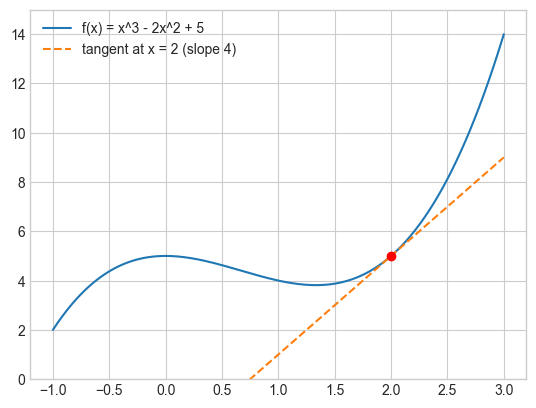

In [3]:
# Check: compare the analytic derivative with a central finite difference and plot the tangent at x = 2
h = 1e-5
print(f"finite-difference estimate at x=2: {(f(2 + h) - f(2 - h)) / (2 * h):.5f}")
xs = np.linspace(-1, 3, 200)
plt.plot(xs, f(xs), label="f(x) = x^3 - 2x^2 + 5")
plt.plot(xs, f(2) + df(2) * (xs - 2), "--", label="tangent at x = 2 (slope 4)")
plt.scatter([2], [f(2)], color="red", zorder=3)
plt.legend(); plt.ylim(0, 15); plt.show()

---
## 2. Going Multivariate: The Gradient (∇)

Most functions in machine learning have many inputs. The **gradient** is a vector that contains the partial derivative with respect to each input. It points in the direction of the steepest ascent of the function.

### Exercise 2.1: Calculating a Gradient

Consider the function $f(w_1, w_2) = 2w_1^2 + 3w_2^2$.

Your task is to write a Python function `gradient_f` that takes a point `(w_1, w_2)` as a NumPy array and returns the gradient vector $\nabla f = \begin{bmatrix} \frac{\partial f}{\partial w_1} \\ \frac{\partial f}{\partial w_2} \end{bmatrix}$ at that point.

In [4]:
import numpy as np

def gradient_f(w):
    """
    Calculates the gradient of f(w1, w2) = 2*w1^2 + 3*w2^2.
    
    Args:
        w (np.ndarray): A 2D NumPy array [w1, w2].
        
    Returns:
        np.ndarray: The gradient vector [df/dw1, df/dw2].
    """
    w1, w2 = w
    grad_w1 = 4 * w1
    grad_w2 = 6 * w2
    return np.array([grad_w1, grad_w2])   

# Calculate the gradient at the point (w1=1, w2=3)
w_point = np.array([1, 3])
grad_vector = gradient_f(w_point)

print(f"The gradient at {w_point} is: {grad_vector}")

The gradient at [1 3] is: [ 4 18]


---
## 3. The Chain Rule: Backpropagation's Secret Sauce 

Neural networks are nested functions. To find the derivative of the loss with respect to a weight deep inside, we use the chain rule.

### Exercise 3.1: A Manual Backpropagation Step

Imagine a tiny piece of a neural network:
1.  A neuron computes a value: $a = wx + b$
2.  An activation function is applied: $h = \text{sigmoid}(a)$
3.  A squared error loss is computed: $L = (y - h)^2$

Using the chain rule, we know that $\frac{\partial L}{\partial w} = \frac{\partial L}{\partial h} \cdot \frac{\partial h}{\partial a} \cdot \frac{\partial a}{\partial w}$.

Your task is to calculate each of these derivatives and combine them to find the final gradient `dL_dw`.

In [5]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Let's assume some values for our variables
w = 0.5
x = 2.0
b = -1.0
y = 1.0 # The true label

# --- FORWARD PASS ---
a = w * x + b
h = sigmoid(a)
L = (y - h)**2

print(f"Forward Pass Results:")
print(f"a = {a:.4f}, h = {h:.4f}, L = {L:.4f}")

# --- BACKWARD PASS (GRADIENT CALCULATION) ---

# 1. Calculate dL/dh (Derivative of loss w.r.t. h)
dL_dh = -2 * (y - h)

# 2. Calculate dh/da (Derivative of sigmoid w.r.t. a)
dh_da = h * (1 - h)

# 3. Calculate da/dw (Derivative of 'a' w.r.t. w)
da_dw = x

# 4. Combine them using the chain rule
dL_dw = dL_dh * dh_da * da_dw

print(f"\nBackward Pass Gradient:")
print(f"dL/dw = {dL_dw:.4f}")

Forward Pass Results:
a = 0.0000, h = 0.5000, L = 0.2500

Backward Pass Gradient:
dL/dw = -0.5000


---
## 4. Probability: Handling Uncertainty

The next sections will cover foundational probability concepts that are crucial for understanding and building machine learning models.

### Exercise 4.1: The Frequentist Approach in Action

The frequentist view defines probability as the long-run frequency of an event. Let's simulate this by flipping a virtual coin.

Your task is to simulate flipping a fair coin `n` times and calculate the estimated probability of getting heads. Use `np.random.rand()` which gives a random number in `[0, 1)`. Assume heads if the number is `< 0.5`.

In [6]:
def estimate_heads_probability(n):
    """
    Simulates n coin flips and returns the estimated probability of heads.
    """
    # Generate n random numbers between 0 and 1
    flips = np.random.rand(n)
    
    # Count how many of these are 'heads' (e.g., < 0.5)
    num_heads = np.sum(flips < 0.5)
    
    # Calculate the estimated probability
    return num_heads / n

# Test the function with different numbers of flips
print(f"Estimated P(Heads) with 10 flips: {estimate_heads_probability(10)}")
print(f"Estimated P(Heads) with 1000 flips: {estimate_heads_probability(1000)}")
print(f"Estimated P(Heads) with 1000000 flips: {estimate_heads_probability(1000000)}")

Estimated P(Heads) with 10 flips: 0.3
Estimated P(Heads) with 1000 flips: 0.519
Estimated P(Heads) with 1000000 flips: 0.499207


### Exercise 4.2: The Bayesian Approach with Code

Bayesian inference is about updating our beliefs. Let's solve a classic problem:

**Problem:** A medical test for a disease is 99% accurate (it's positive for 99% of people with the disease and negative for 99% of people without it). The disease affects 1% of the population. If a patient tests positive, what is the actual probability they have the disease?

Use Bayes' Theorem: $P(\text{Disease} | \text{Positive}) = \frac{P(\text{Positive} | \text{Disease}) \cdot P(\text{Disease})}{P(\text{Positive})}$

Where $P(\text{Positive}) = P(\text{Positive} | \text{Disease})P(\text{Disease}) + P(\text{Positive} | \text{No Disease})P(\text{No Disease})$.

Your task is to fill in the variables and calculate the posterior probability.

In [7]:
# Given information
p_disease = 0.01
p_pos_given_disease = 0.99
p_pos_given_no_disease = 0.01

# 1. Calculate P(No Disease)
p_no_disease = 1 - p_disease

# 2. Calculate the total probability of testing positive, P(Positive)
p_positive = (p_pos_given_disease * p_disease) + (p_pos_given_no_disease * p_no_disease)

# 3. Apply Bayes' Theorem to find the posterior probability
p_disease_given_pos = (p_pos_given_disease * p_disease) / p_positive

print(f"Prior probability of having the disease: {p_disease:.2%}")
print(f"After testing positive, the updated probability is: {p_disease_given_pos:.2%}")

Prior probability of having the disease: 1.00%
After testing positive, the updated probability is: 50.00%


---
## 5. Jacobians and Probability Distributions

Let's move on to some more challenging problems that are highly relevant in machine learning.

### Exercise 5.1: The Jacobian Matrix

The Jacobian matrix is the generalization of the gradient for vector-valued functions. It represents the best linear approximation of the function at a point.

Consider the function $f(x, y) = \begin{bmatrix} f_1(x, y) \\ f_2(x, y) \end{bmatrix} = \begin{bmatrix} x^2 \sin(y) \\ y^2 \cos(x) \end{bmatrix}$.

The Jacobian matrix $J$ is defined as $J = \begin{bmatrix} \frac{\partial f_1}{\partial x} & \frac{\partial f_1}{\partial y} \\ \frac{\partial f_2}{\partial x} & \frac{\partial f_2}{\partial y} \end{bmatrix}$.

**Your Task:** Write a function that computes the Jacobian matrix for $f(x, y)$ at a given point `(x, y)`.

In [8]:
def compute_jacobian(point):
    """
    Computes the Jacobian of f(x,y) = [x^2*sin(y), y^2*cos(x)].
    Args:
        point (np.ndarray): A 2D NumPy array [x, y].
    Returns:
        np.ndarray: The 2x2 Jacobian matrix.
    """
    x, y = point
    
    # Partial derivatives of f1 = x^2 * sin(y)
    df1_dx = 2 * x * np.sin(y)
    df1_dy = x**2 * np.cos(y)
    
    # Partial derivatives of f2 = y^2 * cos(x)
    df2_dx = -y**2 * np.sin(x)
    df2_dy = 2 * y * np.cos(x)
    
    # Assemble the Jacobian matrix
    J = np.array([[df1_dx, df1_dy],
                  [df2_dx, df2_dy]])
    
    return J


# Compute the Jacobian at (x=pi/2, y=pi/3)
point = np.array([np.pi/2, np.pi/3])
jacobian = compute_jacobian(point)

print(f"Point (x, y): ({point[0]:.2f}, {point[1]:.2f})")
print(f"Jacobian matrix:\n{np.round(jacobian, 4)}")

Point (x, y): (1.57, 1.05)
Jacobian matrix:
[[ 2.7207  1.2337]
 [-1.0966  0.    ]]


### Exercise 5.2: Joint and Conditional Probability

Let's analyze a dataset of weather and activity choices. The **joint probability** $P(\text{Weather}, \text{Activity})$ is given in the table below.

|            | Walk  | Shop  | Clean |
|------------|-------|-------|-------|
| **Sunny** | 0.25  | 0.15  | 0.05  |
| **Cloudy** | 0.10  | 0.10  | 0.10  |
| **Rainy** | 0.00  | 0.05  | 0.20  |

**Your Tasks:**
1.  Calculate the **marginal probability** of it being 'Rainy', $P(\text{Weather=Rainy})$.
2.  Calculate the **conditional probability** of choosing to 'Clean' given that it is 'Rainy', $P(\text{Activity=Clean} | \text{Weather=Rainy})$.

*Hint: $P(A|B) = \frac{P(A, B)}{P(B)}$*

In [9]:
# Joint probability table P(Weather, Activity)
# Rows: 0:Sunny, 1:Cloudy, 2:Rainy
# Cols: 0:Walk,  1:Shop,   2:Clean
joint_prob = np.array([
    [0.25, 0.15, 0.05], # Sunny
    [0.10, 0.10, 0.10], # Cloudy
    [0.00, 0.05, 0.20]  # Rainy
])

# 1. Calculate the marginal probability P(Weather=Rainy)
# Hint: Sum the probabilities in the 'Rainy' row.
p_rainy = np.sum(joint_prob[2, :])
print(f"Marginal probability P(Weather=Rainy): {p_rainy:.2f}")

# 2. Calculate the conditional probability P(Activity=Clean | Weather=Rainy)
# Hint: Use the formula P(A|B) = P(A and B) / P(B)
# P(Activity=Clean and Weather=Rainy) is a value from the table.
p_clean_and_rainy = joint_prob[2, 2]
p_clean_given_rainy = p_clean_and_rainy / p_rainy
print(f"Conditional probability P(Activity=Clean | Weather=Rainy): {p_clean_given_rainy:.2f}")

Marginal probability P(Weather=Rainy): 0.25
Conditional probability P(Activity=Clean | Weather=Rainy): 0.80


### Exercise 5.3: Expected Value and Variance

The **expected value** $E[X]$ is the long-term average value of a random variable, while the **variance** $\text{Var}(X)$ measures its spread or dispersion.

* $E[X] = \sum_i x_i P(x_i)$
* $\text{Var}(X) = E[(X - E[X])^2] = \sum_i (x_i - E[X])^2 P(x_i)$

Consider a loaded die where the outcomes and their probabilities are:
* Outcomes `X`: `[1, 2, 3, 4, 5, 6]`
* Probabilities `P(X)`: `[0.1, 0.1, 0.1, 0.1, 0.1, 0.5]`

**Your Task:** Write functions to calculate the expected value and variance for this loaded die.

In [10]:
outcomes = np.array([1, 2, 3, 4, 5, 6])
probs = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.5])

def calculate_expected_value(x, p):
    return np.sum(x * p)

def calculate_variance(x, p):
    # Hint: You'll need the expected value first.
    mu = calculate_expected_value(x, p)
    return np.sum(((x - mu) ** 2) * p)

expected_value = calculate_expected_value(outcomes, probs)
variance = calculate_variance(outcomes, probs)

print(f"The expected value of the loaded die is: {expected_value:.2f}")
print(f"The variance of the loaded die is: {variance:.2f}")

The expected value of the loaded die is: 4.50
The variance of the loaded die is: 3.25
